# Market direction research: an auditable walkthrough
**Divya Mistry** · Financial machine learning

This notebook connects the research question to data timing, model comparisons and financial outcomes. Run it from this checkout after `pip install -e '.[dev]'`. It uses committed artifacts and does not download data or silently refit models.

The central question is incremental predictive information, followed by a separate question about net trading performance. Positive historical returns and proven alpha are different claims.


In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from market_direction.data import ROOT, verify
from market_direction.features import build, FEATURE_SETS
from market_direction.evaluation import returns_for, finance

original = json.loads((ROOT / 'reports/metrics.json').read_text())
extension = json.loads((ROOT / 'experiments/v2/reports/metrics.json').read_text())
manifest = verify()
print('Verified source files:', ', '.join(manifest['files']))
print('Original holdout:', original['holdout'])


Verified source files: prices.csv, macro.csv, sentiment.csv
Original holdout: {'start': '2022-01-03', 'end': '2025-12-31', 'rows': 1003, 'up_rate': 0.5383848454636092}


## 1. Observe features before the next-session outcome

Macro and news series are joined backward on an assumed availability date. No future observation backfills a missing value. These are latest-vintage snapshots; the lag assumptions do not certify point-in-time tradability.


In [2]:
features = build()
preview = features[['signal_date', 'trade_date', 'return_5d', 'news_sentiment', 'yield_curve', 'inflation_yoy', 'target_up']].tail()
print(preview.to_string(index=False))
assert (features.trade_date > features.signal_date).all()
for name in features.filter(like='_available_date'):
    assert (features[name] <= features.signal_date).all()
print('Timing checks passed. Original feature count:', len(FEATURE_SETS['Full']))


signal_date trade_date  return_5d  news_sentiment  yield_curve  inflation_yoy  target_up
 2025-12-23 2025-12-24   0.016384        0.019541         0.68       3.022572          1
 2025-12-24 2025-12-26   0.031308        0.002072         0.73       3.022572          0
 2025-12-26 2025-12-29   0.023475       -0.019854         0.68       3.022572          1
 2025-12-29 2025-12-30   0.010667       -0.023938         0.68       3.022572          0
 2025-12-30 2025-12-31   0.003183       -0.000531         0.68       3.022572          0
Timing checks passed. Original feature count: 24


## 2. Compare model families and feature ablations

The original winner is chosen on mean annual validation balanced accuracy, not the best test return. A lower-complexity baseline can legitimately beat a more complex model. Negative incremental results for sentiment should not be hidden.


In [3]:
comparison = pd.DataFrame([{
    'model': m['family'], 'features': m['features'],
    'validation_ba': m['cv_balanced_accuracy'],
    'test_ba': m['holdout']['balanced_accuracy'],
    'test_auc': m['holdout']['roc_auc'],
    'net_total_return': m['strategy']['total_return'],
    'net_sharpe': m['strategy']['sharpe']
} for m in original['models']]).sort_values('validation_ba', ascending=False)
print(comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print('Selected on validation:', original['selected_model'])


            model           features  validation_ba  test_ba  test_auc  net_total_return  net_sharpe
         Logistic               Full         0.5148   0.4860    0.4876            0.1215      0.4012
         CatBoost             Market         0.5065   0.5086    0.5386            0.2543      0.6858
         CatBoost Market + sentiment         0.5026   0.4989    0.5033            0.0939      0.2559
Majority baseline               None         0.5000   0.5000    0.5000            0.0000      0.0000
         CatBoost     Market + macro         0.4991   0.5140    0.5363            0.3727      0.7784
    Random Forest             Market         0.4973   0.5153    0.5109           -0.0439     -0.0697
    Random Forest Market + sentiment         0.4945   0.4935    0.5096           -0.0617     -0.1267
         CatBoost               Full         0.4862   0.5108    0.5135            0.2748      0.6281
    Random Forest               Full         0.4857   0.4991    0.5092            0.0662   

## 3. Recompute P&L rather than trusting a headline

Every active day pays both entry and exit costs. Two consecutive active days are two round trips because the strategy is flat overnight. The buy-and-hold benchmark includes overnight exposure and is not risk-equivalent to the model strategy.


{
  "total_return": 0.12146277896929547,
  "annual_return": 0.02922010437697331,
  "annual_volatility": 0.07935083395370059,
  "sharpe": 0.40123801900194117,
  "max_drawdown": -0.06975598708950392,
  "exposure": 0.10069790628115653,
  "round_trips": 101,
  "hit_rate": 0.5247524752475248,
  "profit_factor": 1.32318194825463
}


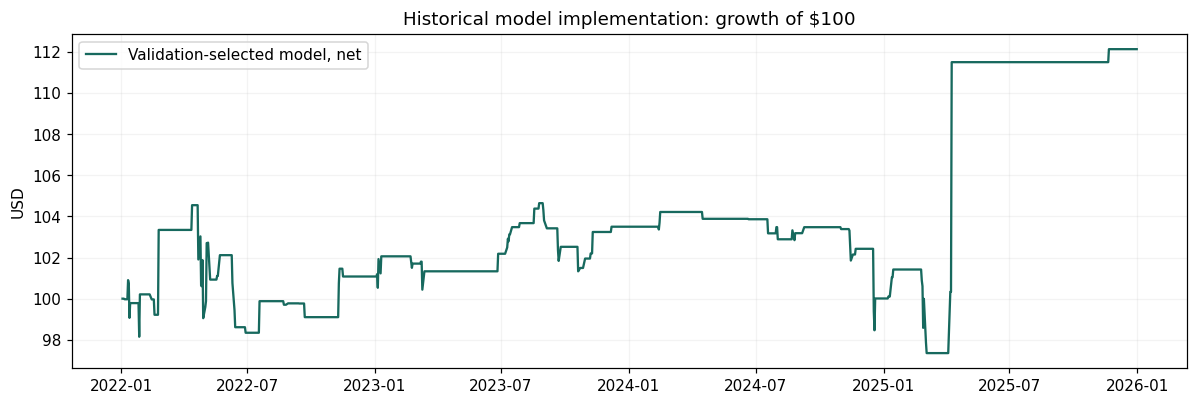

In [4]:
predictions = pd.read_csv(ROOT / 'reports/predictions.csv')
chosen = predictions.loc[predictions.model == original['selected_model']]
position, net = returns_for(chosen.probability_up, chosen.market_return, threshold=.55, cost_bps=2)
statistics = finance(net, position)
print(json.dumps(statistics, indent=2))
assert abs(statistics['total_return'] - .12146277351617352) < 1e-6
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(pd.to_datetime(chosen.date), 100 * np.cumprod(1 + net), label='Validation-selected model, net', color='#17695e')
ax.set(title='Historical model implementation: growth of $100', ylabel='USD')
ax.grid(alpha=.15); ax.legend(); plt.tight_layout(); plt.show()


## 4. Preserve the first result and test the extension separately

The original 2022–2025 period was observed before the extension. The extension promotes it to development and reserves January–October 2026. Its protocol was committed before scoring that new period. The search adds reversal, cross-asset features, rolling training windows and development-selected thresholds.

Fresh CatBoost directional performance improves, but its fixed trading overlay is negative after costs. The confidence interval includes chance. That distinction is part of the conclusion, not an omitted caveat.


In [5]:
print('Selected extension:', {k:v for k,v in extension['selected'].items() if k != 'columns'})
print('Fresh direction metrics:', extension['classification'])
print('Always-up baseline:', extension['majority'])
print('Balanced accuracy interval:', extension['direction_interval'])
print('Fresh financial outcomes:', extension['strategy'])


Selected extension: {'family': 'CatBoost', 'features': 'Enhanced market', 'depth': 4, 'window': 5, 'id': 'extension_04', 'threshold': 0.58, 'cv_balanced_accuracy': 0.5202334763492488, 'cv_auc': 0.5149370516728549, 'annual_balanced_accuracy': {'2019': 0.5469107551487414, '2020': 0.5037543319214478, '2021': 0.520596635988575, '2022': 0.48679197358394716, '2023': 0.5035004292979328, '2024': 0.537037037037037, '2025': 0.5430431714670602}}
Fresh direction metrics: {'accuracy': 0.5311004784688995, 'balanced_accuracy': 0.5352628686572632, 'roc_auc': 0.5263784575929658, 'brier': 0.2509294115477042, 'log_loss': 0.6950421288184353}
Always-up baseline: {'accuracy': 0.507177033492823, 'balanced_accuracy': 0.5, 'roc_auc': 0.5, 'brier': 0.2510258373205741, 'log_loss': 0.6952066798914892}
Balanced accuracy interval: {'lower_95': 0.48243635767085474, 'upper_95': 0.5862168171192931, 'block_sessions': 10, 'repetitions': 1000}
Fresh financial outcomes: {'total_return': -0.004429560787740927, 'annual_retu

## 5. Inspect additional historical profit comparisons

Extra Trees and histogram gradient boosting were added after the original holdout was inspected. Their results are historical backtests on a reused sample. The validation-profit winner and the highest retrospective return must not be conflated.


In [6]:
profit = json.loads((ROOT / 'reports/profitability.json').read_text())
financial_comparison = pd.DataFrame([{
    'model': m['family'], 'features': m['features'],
    'validation_sharpe': m['cv_net_sharpe'],
    'historical_net_return': m['strategy']['total_return'],
    'max_drawdown': m['strategy']['max_drawdown']
} for m in profit['models']]).sort_values('validation_sharpe', ascending=False)
print(financial_comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print('Selected by validation net Sharpe:', profit['selected_on_validation'])


            model           features  validation_sharpe  historical_net_return  max_drawdown
         Logistic               Full             0.1220                 0.1215       -0.0698
      Extra Trees             Market             0.0804                -0.0215       -0.0681
Majority baseline               None             0.0000                 0.0000        0.0000
     Histogram GB               Full            -0.0578                 0.1337       -0.1183
         CatBoost             Market            -0.1352                 0.2543       -0.1059
     Histogram GB             Market            -0.1553                 0.1504       -0.1513
      Extra Trees               Full            -0.1886                 0.0155       -0.0241
         CatBoost               Full            -0.2219                 0.2748       -0.0830
         CatBoost Market + sentiment            -0.2523                 0.0939       -0.1809
         CatBoost     Market + macro            -0.4809               

## 6. Reproduce training and extend responsibly

Run from the checkout terminal:

```bash
market-direction run
market-direction extension-run
market-direction profitability
pytest -q
```

For the next independent research step, freeze the decision rule and collect forward paper-trading observations. Obtain actual publication vintages and realistic fills before treating this as an investment strategy. See the model card for data, inference and implementation limits.
